# Vision Project - Notebook 1
## Data Annotation for Passport Text Detection & Extraction

> **Audience:** AI students and AI engineers starting a real document-AI project.

> **Goal of this notebook:** Understand *why* annotation is the foundation step, *how* to do it professionally with labelImg in YOLO format, and *what* the industry actually uses at scale.

---

### Project Context

We are building a passport information extraction system. Reality of our current dataset:

| Property | Value |
|---|---|
| Total images | 50 (≈2% of a real production dataset) |
| Country coverage | 1 country (single nationality) |
| View | Front side only (data page) |
| Years covered | 2016 – 2026 (multiple passport designs) |
| Image quality | Mixed — clean scans, blurry phone shots, color variations, lighting differences |

### Fields we need to extract

1. `first_name`
2. `last_name`
3. `passport_no`
4. `nationality`
5. `dob` *(optional — include if visible)*

### The full pipeline (high-level)

```
Passport image  ──▶  Object Detection (YOLO)  ──▶  Crops per field  ──▶  OCR (EasyOCR) per crop  ──▶  Structured JSON
```

**This notebook stops at preparing the labels.** Training comes in `vision-v2.ipynb`.

---

## Part 1 — What is Data Annotation?

**Data annotation** is the process of attaching meaningful labels to raw data so that a AI model can learn the mapping from `input → desired output`.

For computer vision specifically, annotation comes in several flavors:

| Task | What you label |
|---|---|
| Image classification | One label per image (e.g. `cat`, `kangaroo`) |
| **Object detection** | **Bounding boxes + class names — what we need** |
| Semantic segmentation | A class per pixel |
| Instance segmentation | A mask per individual object |
| Keypoint detection | Coordinates of fixed landmarks (face, pose) |

For our passport project we need **object detection** — drawing rectangles around each field and tagging them with the right class.

In AI/computer vision terms:

- Text Detection → object detection problem (find text regions)
- Text Recognition / Extraction → sequence prediction problem (read characters)
- OCR → combines both 

### Why annotation is *the* most important step

A supervised model literally cannot learn anything you don't label. Your annotations *are* the ground truth — the only definition the model has of "correct".

> **Garbage in → garbage out.** Sloppy labels produce sloppy models, regardless of architecture, GPU, or training time. Industry studies routinely find 3–10% label errors in popular benchmark datasets, and *fixing labels* often improves real-world accuracy more than swapping models.

### What good annotation gives you

- Higher final model accuracy
- Faster convergence (fewer epochs needed)
- Fewer false positives in production
- Easier debugging — when the model fails, you can *trust* the labels and look elsewhere
- A reusable asset — the dataset outlives any single model

## Part 2 — Why Annotate *Before* OCR?

This is the most common beginner question on document-AI projects:

> *"We already have OCR engines like Tesseract, EasyOCR, PaddleOCR and TrOCR. Why not just feed the whole passport image to OCR and be done with it?"*

Let's look at what actually happens if you skip detection and run OCR directly on a raw passport.

### What goes wrong with "OCR-only"

1. **OCR returns *every* piece of text on the page.** That includes:
   - Document headers (`PASSPORT`, `REPUBLIC OF X`)
   - The MRZ (machine-readable zone) at the bottom — long strings of `<<<` characters
   - The country name, issuing authority, security text
   - Watermarks and decorative text
2. **OCR has no idea which string is a first name vs. a passport number.** It returns text, not meaning.
3. **Field positions change between passport designs.** Your hand-written rule "first name is on line 3" breaks the moment the 2019 redesign moves it to line 4.
4. **Noise on irrelevant regions hurts everything.** OCR's confidence drops on cluttered images, even if the field you actually care about is clean.
5. **It's slower.** OCR on the full page is many times slower than OCR on a 200×40 px crop.

### The detection-first pipeline (industry standard)

```
        ┌──────────────┐
        │ Raw passport │
        └──────┬───────┘
               │
               ▼
   ┌────────────────────────┐
   │  Object detector (YOLO)│   ← trained on YOUR annotations
   │  outputs bounding boxes│
   └──────┬─────────────────┘
          │
   ┌──────┴────────┬─────────────┬──────────────┐
   ▼               ▼             ▼              ▼
 first_name    last_name     passport_no   nationality   ...crops
   │               │             │              │
   ▼               ▼             ▼              ▼
  OCR             OCR           OCR            OCR
   │               │             │              │
   └───────────────┴─────┬───────┴──────────────┘
                         ▼
              ┌─────────────────────┐
              │  Structured output  │
              │  { "first_name": …, │
              │    "passport_no": …}│
              └─────────────────────┘
```

This two-stage approach:

- **Localizes first**, OCRs second → each OCR call works on a clean, tightly cropped region
- **Maps text to field name automatically** because the box already carries a class
- Is **robust to layout changes** — the detector handles "where", OCR handles "what"
- Is what Google Document AI, Amazon Textract, and most real-world document pipelines do internally

### Bottom line

> **Annotation isn't extra work before OCR — annotation is what *makes OCR usable* for structured documents.** Without it you have a text dump, not data.

---

## Part 3 — The Annotation Tools Landscape

There are dozens of tools. Here's a curated map.

### Online / Cloud-based

| Tool | Free tier | Best for |
|---|---|---|
| **Roboflow** | Yes (limited dataset size) | YOLO export, dataset versioning, very popular for hobbyist + small team |
| **CVAT (cvat.ai)** | Yes | Open source, hosted version available, good for teams |
| **Label Studio (cloud)** | Yes | Most flexible — text, audio, video, images all in one |
| **Makesense.ai** | Yes | Browser-only, *zero signup*, perfect for quick jobs |
| **V7 Darwin** | Trial | AI-assisted polygon/segmentation |
| **Labelbox** | Trial | Enterprise-grade QA workflows |
| **SuperAnnotate** | Trial | Strong project management features |

### Offline / Self-hosted (free)

| Tool | Best for |
|---|---|
| **labelImg** | Quick bounding-box annotation, YOLO/PASCAL VOC export — *what we'll use* |
| **LabelMe** | Polygon annotation, lightweight |
| **CVAT (Docker)** | Team workflows on-prem, video annotation |
| **Label Studio (local)** | Multimodal projects |
| **AnyLabeling** | Modern labelImg-style UI + Segment Anything (SAM) auto-labeling |
| **X-AnyLabeling** | AnyLabeling with even more built-in models |

### Why labelImg for us

- 50 images, single annotator, simple bounding boxes — labelImg is the fastest path from zero to YOLO labels.
- Native YOLO `.txt` export → drops straight into Ultralytics training format.
- Keyboard-driven workflow, no internet required, runs on any laptop.

> **Heads-up:** labelImg's original GitHub repo was archived in 2022. It still works perfectly, but if you want AI-assisted labeling consider **AnyLabeling** as a drop-in successor with the same look-and-feel plus auto-segmentation.

---

## Part 4 — labelImg, Used Properly

### 4.1 Install

Pick whichever fits your environment. From a terminal in the project root:

In [8]:
# OPTION A — install into the project's uv environment (recommended)
# Run this in a terminal, not in the notebook:
#
#     uv add --dev labelImg
#
# OPTION B — install globally with pipx (isolated)
#
#     pipx install labelImg
#
# OPTION C — plain pip (if uv/pipx aren't set up yet)
#
#     pip install labelImg
#
# Launch the GUI:
#
#     labelImg
#
# If you hit Qt/GLIBC errors on Linux, install PyQt5 system packages:
#     sudo apt install python3-pyqt5

### 4.2 One-time setup for our project

Open labelImg, then in this exact order:

1. **Open Dir** → select `ai/notebooks/raw_data/images`
2. **Change Save Dir** → select `ai/notebooks/raw_data/labels`
   *(later we'll split into `train/` and `val/`; for now save everything flat — a script in notebook 2 will move them)*
3. **Switch format to YOLO** — there's a button on the left toolbar that toggles between `PascalVOC ⇄ YOLO`. Make sure it shows **YOLO**.
4. **Define your class list** — labelImg reads from a file called `classes.txt`. Create it in the *save dir* (or in labelImg's own `data/` folder) with our exact classes:

```
first_name
last_name
passport_no
nationality
dob
```

> **Why a fixed class list matters:** Without it, every annotator types class names freely and you end up with `passport_no`, `passport_number`, `Passport No`, `passportno` all in the same dataset. The model treats those as 4 different classes, training silently fails, and you spend a day debugging.

We'll create this file from Python now, in the right place.

In [9]:
# from pathlib import Path

# # Adjust if you're running from a different working directory.
# # This notebook lives in ai/notebooks/, so the dataset folder is alongside it.
# NOTEBOOK_DIR = Path.cwd()                       # ai/notebooks/
# DATASET_DIR  = NOTEBOOK_DIR / "dataset"
# LABELS_DIR   = DATASET_DIR / "labels"
# RAW_IMAGES   = NOTEBOOK_DIR / "raw_data" / "images"

# CLASSES = ["first_name", "last_name", "passport_no", "nationality", "dob"]

# LABELS_DIR.mkdir(parents=True, exist_ok=True)

# classes_file = LABELS_DIR / "classes.txt"
# classes_file.write_text("\n".join(CLASSES) + "\n")

# print(f"Wrote {classes_file}")
# print("---")
# print(classes_file.read_text())

### 4.3 The actual annotation workflow

For each image:

1. Press **`W`** → enter "draw box" mode
2. Click-and-drag a tight rectangle around a field (e.g. the printed first name)
3. Release → a popup appears → pick the matching class
4. Repeat for all 5 fields on this passport
5. **`Ctrl + S`** → save (creates `image_001.txt` in your save dir)
6. **`D`** → next image
7. Loop until done

### 4.4 Keyboard shortcuts that 5x your speed

Memorize these. The GUI is just a fallback.

| Shortcut | Action |
|---|---|
| `W` | Create new bounding box |
| `D` | Next image |
| `A` | Previous image |
| `Ctrl + S` | Save |
| `Del` | Delete selected box |
| `Ctrl + D` | Duplicate selected box (great for repeating layouts) |
| `Ctrl + +` / `Ctrl + -` | Zoom in / out |
| `Ctrl + F` | Fit window |
| `Space` | Mark image as "verified" (visual flag in the file list) |
| `↑ ↓ ← →` | Nudge selected box by 1 pixel |

> **Pro move:** annotate all 50 images with the keyboard only. Your wrist will thank you and you'll go ~3× faster than mouse-clicking the menu each time.

### 4.5 Best practices (the difference between hobbyist and pro labels)

1. **Box the *value*, not the printed label.**
   The image says `Surname: BILAL` — you box `BILAL`, not `Surname: BILAL`. Your model is learning to find values for OCR; the label text is noise.
2. **Tight, but no clipping.** The box should hug the text without cutting ascenders (`b`, `d`, `h`) or descenders (`g`, `p`, `y`). Loose boxes hurt OCR; clipped boxes hurt detection recall.
3. **Be consistent across the whole dataset.** If on image #3 you decided "include the diacritics", do that on all 50. Pick a rule, write it down, never break it.
4. **Don't skip blurry / damaged samples — annotate them.** Skipping = your model never learns to handle them. The whole reason you're shipping ML instead of regex is to handle the messy cases.
5. **Annotate partial / occluded fields.** If half a passport number is cut off by a finger, label what's visible. Tag it normally — partial visibility is realistic input.
6. **Save every image.** `Ctrl + S` after every annotation. labelImg has been known to crash; an unsaved hour is a painful hour.
7. **Spot-check every 10 images.** Pop one open in a viewer (we'll do this below), make sure boxes line up.
8. **Document edge cases in `ANNOTATION_GUIDELINES.md`.** What about middle names? Two-line surnames? DOB shown as `01 JAN 1990` vs `1990-01-01`? Future-you and second annotators will need this.

---

## Part 5 — Understanding the YOLO Annotation Format

When labelImg saves in YOLO mode, for each image `passport_001.jpg` it writes a sibling text file `passport_001.txt`.

### Format

One line per object:

```
<class_id> <x_center> <y_center> <width> <height>
```

- `class_id` — integer index into `classes.txt` (zero-based)
- `x_center, y_center` — center of the box, **normalized** to `0–1` (i.e. divided by image width / height)
- `width, height` — box size, also **normalized** to `0–1`

### Example

For a passport image, the `.txt` might contain:

```
0 0.512 0.234 0.180 0.045
1 0.512 0.298 0.220 0.045
2 0.612 0.420 0.310 0.040
3 0.488 0.512 0.280 0.040
4 0.488 0.580 0.180 0.040
```

Reading that:

| Line | Class | Meaning |
|---|---|---|
| 0 | `first_name` | small box near the top-center |
| 1 | `last_name` | just below first name |
| 2 | `passport_no` | wider box, right side |
| 3 | `nationality` | center, lower |
| 4 | `dob` | smaller box near bottom |

### Why normalized?

Because YOLO models are trained at multiple input resolutions (320, 640, 1280…). Storing coordinates as fractions makes the labels resolution-independent — resize the image, the labels remain valid.

Let's write a small helper that converts back to pixel coordinates so we can sanity-check our work later.

In [10]:
def yolo_to_xyxy(yolo_line: str, img_w: int, img_h: int):
    """Convert a single YOLO line to (class_id, x1, y1, x2, y2) in pixel coords."""
    parts = yolo_line.strip().split()
    cls = int(parts[0])
    xc, yc, w, h = map(float, parts[1:])
    x1 = (xc - w / 2) * img_w
    y1 = (yc - h / 2) * img_h
    x2 = (xc + w / 2) * img_w
    y2 = (yc + h / 2) * img_h
    return cls, x1, y1, x2, y2


# Quick demo with a synthetic line
demo = "2 0.612 0.420 0.310 0.040"
print(yolo_to_xyxy(demo, img_w=1000, img_h=700))

(2, 456.99999999999994, 280.0, 767.0, 308.0)


## Part 6 — Hands-on with Our Dataset

The cells below are diagnostic. Run them *after* you've labeled a few images in labelImg to verify everything wrote out correctly.

In [11]:
# 6.1 — What's in raw_data?
from pathlib import Path

RAW_IMAGES = Path.cwd() / "raw_data" / "images"
# RAW_LABELS = Path.cwd() / "raw_data" / "labels"   # any pre-existing .txt files

if RAW_IMAGES.exists():
    images = sorted([p for p in RAW_IMAGES.iterdir()
                     if p.suffix.lower() in {".jpg", ".jpeg", ".png"}])
    print(f"Found {len(images)} images in {RAW_IMAGES}")
    for p in images[:5]:
        print(" ", p.name)
    if len(images) > 5:
        print(f"  … and {len(images) - 5} more")
else:
    print(f"{RAW_IMAGES} does not exist yet — create it and drop the 50 passport images in.")

Found 50 images in c:\Abdullah Ahmed\Ai course\Computer Vision\clause-ade\api\notebooks\raw_data\images
  img_00.jpeg
  img_01.jpeg
  img_02.jpeg
  img_03.jpeg
  img_04.jpeg
  … and 45 more


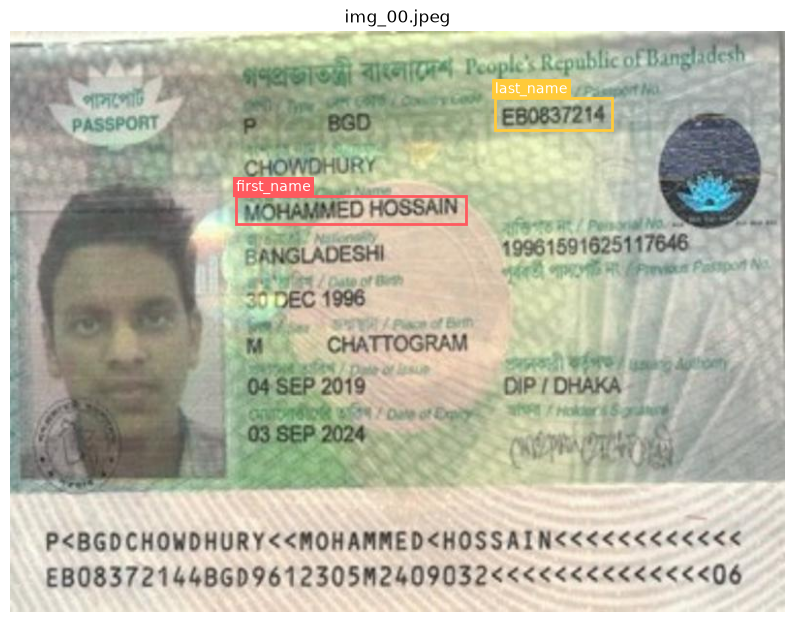

In [12]:
# 6.2 — Visualize one annotation to make sure boxes are right.
# Run this AFTER you've labeled at least one image in labelImg.

import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image
from pathlib import Path


LABELS_DIR = Path.cwd() / "raw_data" / "labels"
RAW_IMAGES = Path.cwd() / "raw_data" / "images"

CLASSES = ["first_name", "last_name", "passport_no", "nationality", "dob"]
# CLASSES = ["personal_no"]
COLORS  = ["#ff595e", "#ffca3a", "#8ac926", "#1982c4", "#6a4c93"]


def show_annotation(image_path: Path, label_path: Path):
    img = Image.open(image_path).convert("RGB")
    W, H = img.size

    fig, ax = plt.subplots(1, figsize=(10, 10))
    ax.imshow(img)
    ax.set_title(image_path.name)
    ax.axis("off")

    if not label_path.exists():
        print(f"No label file at {label_path}")
        plt.show()
        return

    for line in label_path.read_text().strip().splitlines():
        cls, x1, y1, x2, y2 = yolo_to_xyxy(line, W, H)
        color = COLORS[cls % len(COLORS)]
        rect = patches.Rectangle(
            (x1, y1), x2 - x1, y2 - y1,
            linewidth=2, edgecolor=color, facecolor="none",
        )
        ax.add_patch(rect)
        ax.text(
            x1, y1 - 5, CLASSES[cls],
            color="white", fontsize=10,
            bbox=dict(facecolor=color, edgecolor="none", pad=2),
        )
    plt.show()


# Pick the first labeled image automatically
labeled = sorted(LABELS_DIR.glob("*.txt"))
labeled = [p for p in labeled if p.stem != "classes"]   # skip classes.txt

if labeled:
    sample_label = labeled[0]
    # Find the matching image (any common extension)
    for ext in (".jpg", ".jpeg", ".png"):
        candidate = RAW_IMAGES / f"{sample_label.stem}{ext}"
        if candidate.exists():
            show_annotation(candidate, sample_label)
            break
    else:
        print(f"Found label {sample_label.name} but no matching image in {RAW_IMAGES}")
else:
    print("No labels yet. Annotate at least one image in labelImg, then re-run this cell.")

In [13]:
# 6.3 — Sanity check: every image has a label, every label has an image,
#       no class IDs are out of range, no coordinates are out of [0,1].

from pathlib import Path

RAW_IMAGES = Path.cwd() / "raw_data" / "images"
LABELS_DIR = Path.cwd() / "raw_data" / "labels"
NUM_CLASSES = 5
# NUM_CLASSES = 1

img_stems = {p.stem for p in RAW_IMAGES.iterdir()
             if p.suffix.lower() in {".jpg", ".jpeg", ".png"}}
label_stems = {p.stem for p in LABELS_DIR.glob("*.txt") if p.stem != "classes"}

missing_labels = sorted(img_stems - label_stems)
orphan_labels  = sorted(label_stems - img_stems)

print(f"Images:           {len(img_stems)}")
print(f"Label files:      {len(label_stems)}")
print(f"Images missing labels: {len(missing_labels)}")
for s in missing_labels[:10]:
    print(f"   - {s}")
print(f"Orphan label files (no matching image): {len(orphan_labels)}")
for s in orphan_labels[:10]:
    print(f"   - {s}")

# Validate each label file
problems = []
for lbl in LABELS_DIR.glob("*.txt"):
    if lbl.stem == "classes":
        continue
    for i, line in enumerate(lbl.read_text().strip().splitlines(), start=1):
        parts = line.split()
        if len(parts) != 5:
            problems.append((lbl.name, i, "wrong number of values", line))
            continue
        try:
            cls = int(parts[0]); xc, yc, w, h = map(float, parts[1:])
        except ValueError:
            problems.append((lbl.name, i, "non-numeric value", line))
            continue
        if not (0 <= cls < NUM_CLASSES):
            problems.append((lbl.name, i, f"class id {cls} out of range", line))
        for name, val in [("xc", xc), ("yc", yc), ("w", w), ("h", h)]:
            if not (0.0 <= val <= 1.0):
                problems.append((lbl.name, i, f"{name}={val} outside [0,1]", line))

print(f"\nFormat problems: {len(problems)}")
for p in problems[:20]:
    print("  ", p)

Images:           50
Label files:      50
Images missing labels: 0
Orphan label files (no matching image): 0

Format problems: 0


## Part 7 — Manual vs. Semi-Automatic vs. Automatic Annotation

Manual labeling is fine for 50 images. For 5,000 it's a problem. For 500,000 it's a budget. Here's how the industry scales.

### Manual (what we just did)

- **Pros:** Highest accuracy, you own every pixel decision.
- **Cons:** Slow (~1–2 min per image for our task), exhausting, doesn't scale.
- **Sweet spot:** ≤ a few thousand images, or whenever you don't yet have a model good enough to bootstrap from.

### Semi-automatic (recommended once you have any working model)

A pretrained or partially-trained model proposes boxes → a human only **corrects** them. Typical 5–10× speedup.

Tools:
- **AnyLabeling / X-AnyLabeling** — labelImg-style UI with built-in SAM (Segment Anything) for one-click region selection.
- **CVAT** — has "AI tools" that run YOLO/SAM/etc. as you label.
- **Roboflow Smart Polygon / Auto Label** — one-click label assist in the browser.

### Fully automatic (when scale demands it)

A foundation model labels everything → you only **review flagged samples**.

Tools:
- **AutoDistill** — feeds your dataset into a vision-language model (Grounding DINO + SAM) and emits YOLO-format labels from natural-language prompts.
- **YOLO-World** — open-vocabulary detector; describe classes in text and it detects them.
- **Grounded-SAM** — combine Grounding DINO (detect from text) with SAM (segment).

### Free automatic workflow worth trying for our project

The pseudo-code below shows how AutoDistill would auto-label our passport dataset. Even on 50 images this can save an hour, and your only job becomes *review*, not *draw*.

In [14]:
# Pseudo-code — install separately if you want to try this:
#     uv add autodistill autodistill-grounded-sam
#
# from autodistill_grounded_sam import GroundedSAM
# from autodistill.detection import CaptionOntology
#
# ontology = CaptionOntology({
#     "first name on passport":   "first_name",
#     "surname on passport":      "last_name",
#     "passport number":          "passport_no",
#     "nationality field":        "nationality",
#     "date of birth on passport":"dob",
# })
#
# base_model = GroundedSAM(ontology=ontology)
# base_model.label(
#     input_folder="raw_data/images",
#     output_folder="dataset_auto",
#     extension=".jpg",
# )
#
# Output is YOLO-format. Open the predicted labels in labelImg and CORRECT them.
# Never trust foundation-model output blindly — they hallucinate, especially on
# documents with unusual fonts, glare, or partial occlusion.
# print("This is documentation only — uncomment and install dependencies to actually run.")

## Part 8 — Industry Tips You Won't Find in Tutorials

These are the things that separate a hobby project from a deployable system.

### 1. Annotation guidelines beat tools
A 1-page `ANNOTATION_GUIDELINES.md` with screenshots of edge cases is more valuable than upgrading from labelImg to a $50k SaaS. Decisions to document:

- Do we include diacritics in `first_name`?
- Two-line surnames — one box or two?
- DOB shown in two formats on the same passport — which one wins?
- Glare obscures half the passport number — annotate or skip?

### 2. Double-blind annotation for production datasets
Two annotators label the same image independently. You compute IoU agreement. Samples below an IoU threshold (say 0.7) get reviewed by a senior annotator. This is how production labels at autonomous-driving / medical-imaging companies are made.

### 3. Active learning saves money
Train on 20% of your images → run inference on the rest → the *least confident* predictions are the next 20% you label by hand. After 3 rounds you've matched 80% of the accuracy of full labeling for a fraction of the cost. Tools: **modAL**, **cleanlab**, or roll your own with confidence scores.

### 4. Synthetic data fills the long tail
Need a 2017 passport in heavy blur? Don't hunt for one — generate it. Apply Gaussian blur, JPEG compression, lighting variation, perspective warp to your existing samples. Libraries: **albumentations**, **imgaug**, or **Roboflow's preprocessing**.

### 5. Version your dataset like code
"Dataset v1.2" should be exactly reproducible. Tools: **DVC**, **Roboflow versions**, or even just `git lfs` + a manifest file. When your model regresses next month, you'll need to compare against the *exact* dataset that produced the previous good model.

### 6. Privacy is non-negotiable for documents
Passports are PII (personally identifiable information). **Do not push real annotated passports to public GitHub.** Add to your `.gitignore`:

```
ai/notebooks/raw_data/
ai/notebooks/dataset/
*.weights
*.pt
```

For a portfolio version, use synthetic passport templates (there are public ones designed for ML demos) or heavily redact real ones.

### 7. Track per-class metrics from day 1
When you train, you'll see `dob` recall is lower than `passport_no` because:
- DOB has fewer pixels (small font)
- DOB is the "optional" field with fewer labels
- DOB has multiple formats

**Annotation imbalance shows up as model imbalance.** Plan for it now: aim for at least 30 examples per class, and oversample rare classes during training (`weights` parameter in YOLO config).

### 8. Common paid platforms (for context)

| Platform | Niche |
|---|---|
| Scale AI | Big-tech outsourced labeling at huge scale |
| Labelbox | Mid/large enterprise, strong QA |
| SuperAnnotate | Strong project mgmt, good for distributed teams |
| Encord | Medical and computer-vision focused |
| V7 | Fast polygon, AI-assisted |
| Snorkel | Programmatic / weak supervision |

If you're a student or solo engineer, **Roboflow's free tier + labelImg/AnyLabeling** is more than enough for projects up to ~10k images.

---

## Summary & Next Steps

### What we covered
- Why annotation is the foundation step, not an afterthought
- Why detection-first beats OCR-first for structured documents
- The full landscape of online + offline annotation tools
- How to use **labelImg** professionally, with shortcuts and best practices
- The **YOLO label format** in detail, with code to verify it
- **Manual → semi-automatic → automatic** as your dataset grows
- Industry practices: guidelines, IoU agreement, active learning, synthetic data, dataset versioning

### Your action items for this notebook

1. Install labelImg
2. Open `raw_data/images`, set save dir to `raw_data/labels`, switch to YOLO mode
3. Define classes (`first_name, last_name, passport_no, nationality, dob`) — the cell above wrote `classes.txt`
4. Annotate all 50 images (~30–60 min with shortcuts)
5. Run the validation cell — fix any reported issues
6. Spot-check 5 random images with the visualization cell
7. Write a short `ANNOTATION_GUIDELINES.md` covering your edge-case decisions

### Coming next — `vision-v2.ipynb`

- Splitting `raw_data/labels` and `raw_data/images` into `train/` and `val/` (80/20)
- Generating `data.yaml` for Ultralytics
- Training a YOLO detector on our 50 passports (with augmentation to compensate for the small dataset)
- Evaluating per-class precision/recall and identifying which fields need more annotation effort

> **Remember:** Your model will only ever be as good as the labels in this notebook. Slow down here, and the rest of the project becomes much easier.